In [1]:
import openmc
import helpers
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from openmc_model import reactor_model, available_materials

/home/davide/anaconda3/envs/openmc0.15/lib/python3.12/site-packages/openmc/material.py:1444: UserWarning: Warning: sum of fractions do not add to 1, void fraction set to 0.09999999999999987
  warnings.warn(msg)


## Geometry

In [2]:
fw_material = available_materials["zrnbc"]

In [3]:
model, root = reactor_model(fw_material)
geometry = model.geometry

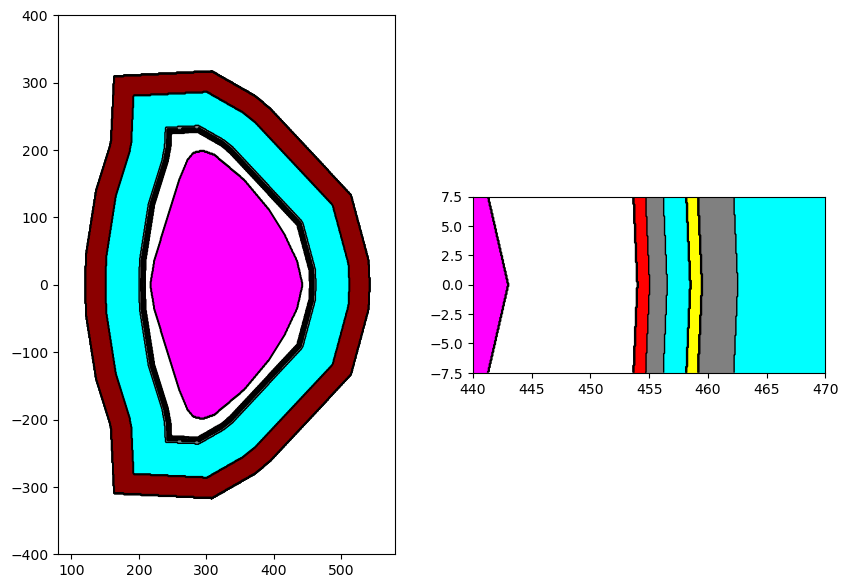

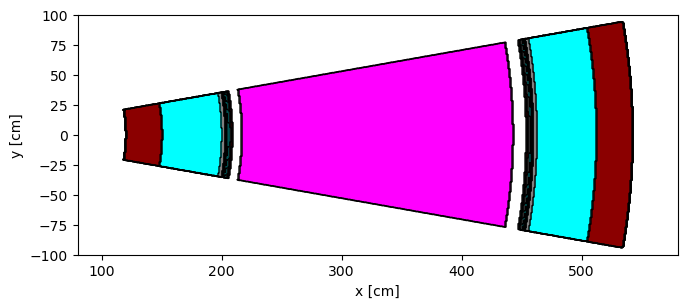

In [4]:
colors={root[0]:'magenta', root[1]:'white', root[2]:'red', root[3]:'grey', root[4]:'aqua', 
        root[5]:'yellow', root[6]:'grey', root[7]:'aqua', root[8]:'darkred', root[9]:'white'}

fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(10,7))
geometry.plot(origin=(330, 0, 0), basis='xz', width=[500, 800], pixels=[600, 600], axes=ax1, 
              color_by='cell', colors=colors, outline=True)
geometry.plot(origin=(455, 0, 0), basis='xz', width=[30, 15], pixels=[400, 400], axes=ax2, 
              color_by='cell', colors=colors, outline=True)
plt.show()

geometry.plot(origin=(330, 0, 0), basis='xy', width=[500, 200], pixels=[600, 600], 
              color_by='cell', colors=colors, outline=True)
plt.show()


## Results
- TBR
- Neutron spectra
- Heating
- DPA

In [5]:
fusion_power = 525e6  # units Watts
energy_per_fusion_reaction = 17.6e6  # units eV
eV_to_Joules = 1.60218e-19  # multiplication factor to convert eV to Joules
number_of_neutrons_per_second = fusion_power / (energy_per_fusion_reaction * eV_to_Joules)
print('Number of neutrons per second', number_of_neutrons_per_second, '\n')

fw_volume = 2234489.71 # units cm^3
fw_surface = 4468977.87 # units cm^2
vessel_inner_volume = 3376578.27 # units cm^3
vessel_inner_surface =  4502100.88 # units cm^2

Number of neutrons per second 1.8618098749544654e+20 



In [6]:
sp = openmc.StatePoint("results/zrnbc.h5")

In [7]:
tbr_total = helpers.extract_tbr_contributions(sp, "TBR")
tbr_cc = helpers.extract_tbr_contributions(sp, "TBR channel")
tbr_blanket = helpers.extract_tbr_contributions(sp, "TBR blanket")

df = pd.DataFrame([tbr_total, tbr_cc, tbr_blanket], index=["Total", "Channel", "Blanket"])
print(df)

              TBR  TBR std. dev.       Li6       Li7
Total    1.044653       0.001264  1.036683  0.007971
Channel  0.254145       0.000451  0.252383  0.001762
Blanket  0.790508       0.001072  0.784300  0.006208


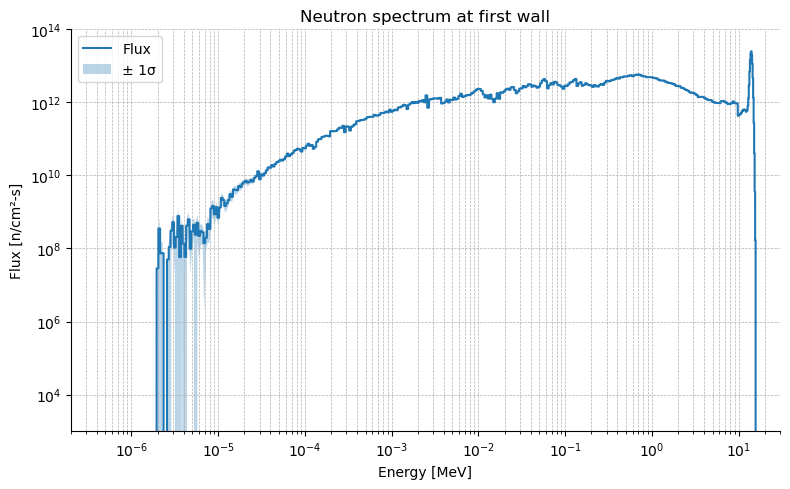

Mean neutron flux: 6.27e+14 ± 6.34e+12 n/cm²-s


In [8]:
tally = sp.get_tally(name="neutron_spectra_fw")

helpers.plot_neutron_spectrum(tally, fw_volume, number_of_neutrons_per_second)

   Particle  Power [MW]
0   Neutron    7.560320
1  Electron   18.041858
2  Positron    0.469450
3    Photon    0.891558
4     Total   26.963186


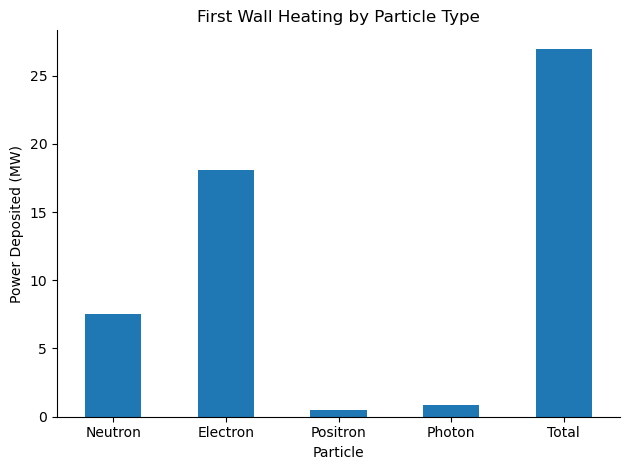

In [9]:
df = helpers.compute_fw_heating(sp, number_of_neutrons_per_second)
print(df)

df.plot(kind='bar', y='Power [MW]', x='Particle', legend=False)
plt.ylabel('Power Deposited (MW)')
plt.title('First Wall Heating by Particle Type')
plt.xticks(rotation=0)
plt.tight_layout()
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

In [10]:
dpa_tally_fw = sp.get_tally(name="dpa_fw")
df_fw = dpa_tally_fw.get_pandas_dataframe()

result = helpers.compute_dpa_from_tally(
    df=df_fw,
    number_of_neutrons_per_second=number_of_neutrons_per_second,  
    atomic_mass_u=helpers.zrnbc_mass_u,                
    density_g_per_cm3=fw_material.density,  
    volume_cm3=fw_volume,
    Ed_eV=helpers.zrnbc_Ed,  
)
print(f"DPA = {result['DPA']}")

DPA = 13.311366439799915
